# 06 - Support Vector Machine (RBF)

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C
from src.features import get_xy
from src.pipeline import build_model, predict_proba
from src.evaluation import evaluate_and_save, plot_curves, score_at, best_threshold
from sklearn.metrics import average_precision_score

df = pd.read_parquet(C.CLEAN_PATH)
X_train, y_train, _ = get_xy(df, "train")
X_val, y_val, _ = get_xy(df, "val")
X_test, y_test, _ = get_xy(df, "test")
print(X_train.shape, X_val.shape, X_test.shape)

(384548, 13) (81129, 13) (80445, 13)


RBF SVM is slow on 380k rows, so we train on a smaller balanced sample (all sepsis rows up to 6000, plus 3x non-sepsis rows). Validation and test sets stay full and untouched.

In [2]:
pos = y_train[y_train == 1].sample(min(6000, int(y_train.sum())), random_state=C.RANDOM_STATE).index
neg = y_train[y_train == 0].sample(len(pos) * 3, random_state=C.RANDOM_STATE).index
idx = pos.union(neg)
Xs, ys = X_train.loc[idx], y_train.loc[idx]
print(Xs.shape, "sepsis share: %.2f" % ys.mean())

(24000, 13) sepsis share: 0.25


## Tuning: C value

In [3]:
grid = [{"C": c} for c in [0.5, 2.0]]
results, models = [], []
for params in grid:
    t = time.time()
    m = build_model("svm", **params)
    m.fit(Xs, ys)
    ap = average_precision_score(y_val, predict_proba(m, X_val))
    results.append({**params, "val_pr_auc": round(ap, 4), "seconds": round(time.time() - t, 1)})
    models.append(m)
tuning = pd.DataFrame(results)
display(tuning.sort_values("val_pr_auc", ascending=False))
i = int(tuning["val_pr_auc"].idxmax())
model, best_params = models[i], grid[i]
print("Best settings:", best_params)

,C,val_pr_auc,seconds
0,0.5,0.0823,468.5
1,2.0,0.0788,217.5


Best settings: {'C': 0.5}


## Evaluate on validation and test

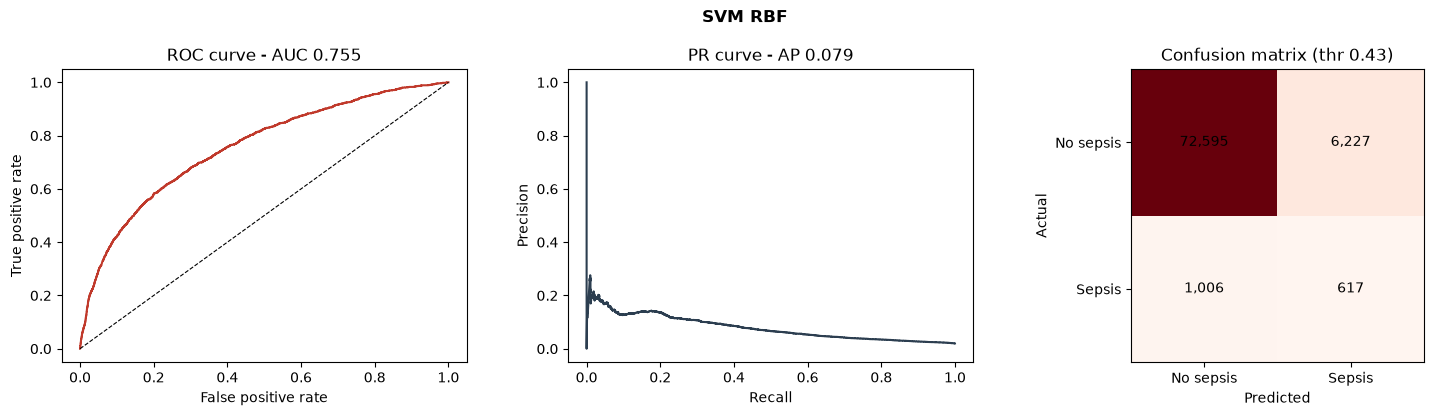

,val,test
roc_auc,0.740,0.755
pr_auc,0.082,0.079
precision,0.097,0.090
recall,0.371,0.380
specificity,0.923,0.921
f1,0.153,0.146
f2,0.237,0.231
balanced_accuracy,0.647,0.651


In [4]:
p_val = predict_proba(model, X_val)
p_test = predict_proba(model, X_test)
res = evaluate_and_save("svm", y_val, p_val, y_test, p_test, extra={"params": best_params, "tuning": tuning.to_dict("records")})
plot_curves(y_test, p_test, "SVM RBF", res["test"]["threshold"])
pd.DataFrame(res).loc[["roc_auc","pr_auc","precision","recall","specificity","f1","f2","balanced_accuracy"], ["val","test"]].round(3)